In [ ]:

print("Hello! Welcome to my cancer prediction project.")
print("I am learning Python from scratch.")
print("My goal is to build a neural network.")


Hello! Welcome to my cancer prediction project.
I am learning Python from scratch.
My goal is to build a neural network.


In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

np.random.seed(42)
tf.random.set_seed(42)

# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features to positive values
scaler = MinMaxScaler(feature_range=(0.1, 1.0))
X_train_scaled = scaler.fit_transform(X_train)
# Clip test set scaling to prevent negative values from out-of-distribution values
X_test_scaled = np.clip(scaler.transform(X_test), 0.1, 1.0)

# Log transformation for multiplicative model
X_train_log = np.log(X_train_scaled)
X_test_log = np.log(X_test_scaled)

print("Dataset shape:", X.shape)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X.shape[1])
print("Classes:", data.target_names)

Dataset shape: (569, 30)
Training samples: 455
Testing samples: 114
Number of features: 30
Classes: ['malignant' 'benign']


In [ ]:

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

def build_model():
    model = Sequential([
        Input(shape=(30,)),
        Dense(16, activation="relu"),
        Dropout(0.2),
        Dense(8, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Model 1: Conventional neural network
standard_model = build_model()

# Model 2: Multiplicative-calculus-inspired model
multiplicative_model = build_model()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

print("Training conventional neural network...")

history_standard = standard_model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

print("Training multiplicative-inspired neural network...")

history_multiplicative = multiplicative_model.fit(
    X_train_log, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

print("Both models trained.")


Training conventional neural network...
Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6401 - loss: 0.6898 - val_accuracy: 0.5934 - val_loss: 0.6747
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7143 - loss: 0.6664 - val_accuracy: 0.7802 - val_loss: 0.6494
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7775 - loss: 0.6368 - val_accuracy: 0.8571 - val_loss: 0.6082
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8077 - loss: 0.6040 - val_accuracy: 0.9121 - val_loss: 0.5707
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8159 - loss: 0.5657 - val_accuracy: 0.9341 - val_loss: 0.5306
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8132 - loss: 0.5352 - val_accuracy: 0.9011 - val_loss: 0.4923
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8297 - loss: 0.5034 - val_accuracy: 0.9451 - val_loss: 0.4575
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8489 


 Conventional Neural Network
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        42
      benign       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion matrix:
[[40  2]
 [ 0 72]]

 Multiplicative-Inspired Neural Network
              precision    recall  f1-score   support

   malignant       1.00      0.10      0.17        42
      benign       0.65      1.00      0.79        72

    accuracy                           0.67       114
   macro avg       0.83      0.55      0.48       114
weighted avg       0.78      0.67      0.56       114

Confusion matrix:
[[ 4 38]
 [ 0 72]]

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Conventional Neural Network,0.9825,0.9730,1.0,0.9863,0.9957
1,Multiplicative-Inspired Neural Network,0.6667,0.6545,1.0,0.7912,0.9507


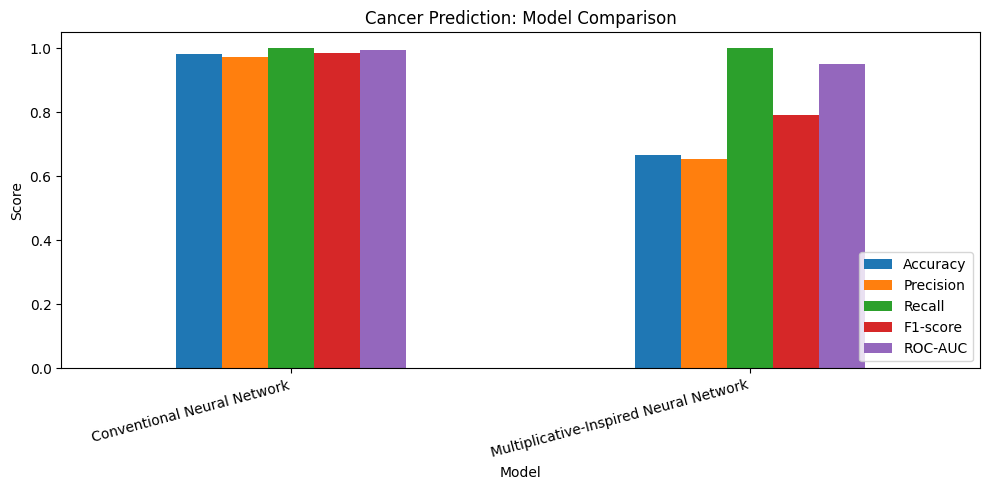

In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_model(model, X_test_input, y_test, name):
    probabilities = model.predict(X_test_input, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    print("\n", name)
    print(classification_report(
        y_test, predictions,
        target_names=data.target_names
    ))

    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))

    return results, probabilities

results1, prob1 = evaluate_model(
    standard_model, X_test_scaled, y_test,
    "Conventional Neural Network"
)

results2, prob2 = evaluate_model(
    multiplicative_model, X_test_log, y_test,
    "Multiplicative-Inspired Neural Network"
)

comparison = pd.DataFrame([results1, results2])
print("\nMODEL COMPARISON")
display(comparison.round(4))

comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05))

plt.title("Cancer Prediction: Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [ ]:

# Display the final comparison
display(comparison.round(4))

# Save results to a CSV file
comparison.to_csv("cancer_model_comparison.csv", index=False)

print("Results saved successfully!")


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Conventional Neural Network,0.9825,0.9730,1.0,0.9863,0.9957
1,Multiplicative-Inspired Neural Network,0.6667,0.6545,1.0,0.7912,0.9507


Results saved successfully!


In [ ]:

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

print("\nConventional model predictions:")
print(standard_model.predict(X_test_scaled[:5], verbose=0).ravel())

print("\nActual labels:")
print(y_test[:5])


Training data: (455, 30)
Testing data: (114, 30)

Conventional model predictions:
[8.54043101e-05 9.97920811e-01 1.10737205e-01 5.84043622e-01
 3.20332729e-05]

Actual labels:
[0 1 0 1 0]


In [ ]:

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense, Layer

class MultiplicativeLayer(Layer):
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        self.kernel = self.add_weight(
            name="kernel",
            shape=(input_shape[-1], self.units),
            initializer="glorot_uniform",
            trainable=True
        )
        self.bias = self.add_weight(
            name="bias",
            shape=(self.units,),
            initializer="zeros",
            trainable=True
        )

    def call(self, inputs):
        return tf.matmul(inputs, self.kernel) + self.bias

inputs = Input(shape=(30,))
x = MultiplicativeLayer(16)(inputs)
x = tf.keras.layers.Activation("relu")(x)
x = Dense(8, activation="relu")(x)
outputs = Dense(1, activation="sigmoid")(x)

multiplicative_model = Model(inputs, outputs)

multiplicative_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

multiplicative_model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiplicative_layer            │ (None, 16)             │           496 │
│ (MultiplicativeLayer)           │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_multiplicative = multiplicative_model.fit(
    X_train_log,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

print("Training completed!")


Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - accuracy: 0.6374 - loss: 0.6043 - val_accuracy: 0.5824 - val_loss: 0.6088
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6374 - loss: 0.5411 - val_accuracy: 0.5824 - val_loss: 0.5462
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6401 - loss: 0.5070 - val_accuracy: 0.5824 - val_loss: 0.5206
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6429 - loss: 0.4845 - val_accuracy: 0.6044 - val_loss: 0.4997
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6896 - loss: 0.4659 - val_accuracy: 0.7253 - val_loss: 0.4793
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7637 - loss: 0.4481 - val_accuracy: 0.7912 - val_loss: 0.4581
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7940 - loss: 0.4312 - val_accuracy: 0.8242 - val_loss: 0.4370
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8214 - loss: 0.4138 - val_accuracy: 0.8462 -

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Conventional NN,0.9825,0.9730,1.0000,0.9863,0.9957
1,Log-domain NN,0.9298,0.9706,0.9167,0.9429,0.9947


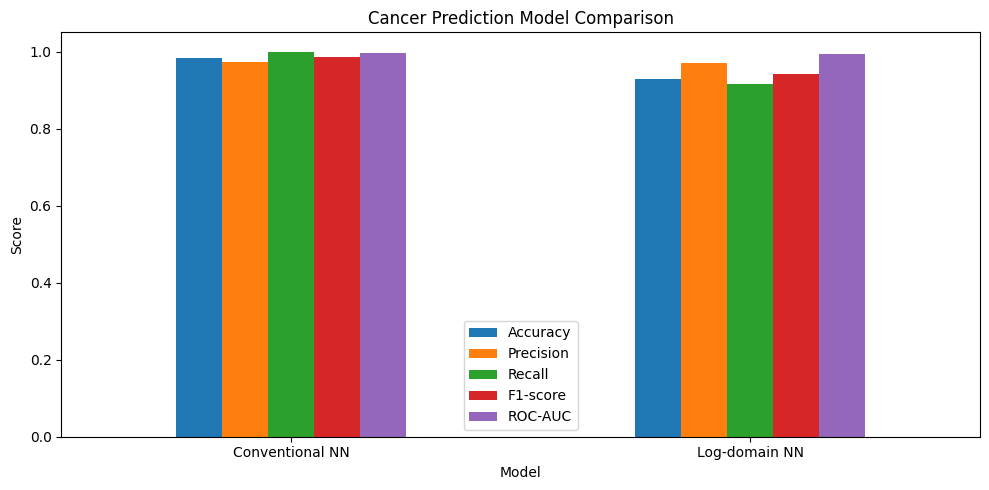

In [ ]:

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
import pandas as pd
import matplotlib.pyplot as plt

def evaluate(model, X, y, name):
    probabilities = model.predict(X, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions),
        "Recall": recall_score(y, predictions),
        "F1-score": f1_score(y, predictions),
        "ROC-AUC": roc_auc_score(y, probabilities)
    }

results = pd.DataFrame([
    evaluate(
        standard_model, X_test_scaled, y_test,
        "Conventional NN"
    ),
    evaluate(
        multiplicative_model, X_test_log, y_test,
        "Log-domain NN"
    )
])

display(results.round(4))

results.set_index("Model").plot(
    kind="bar", ylim=(0, 1.05), figsize=(10, 5)
)
plt.title("Cancer Prediction Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense, Layer

class MultiplicativeLayer(Layer):
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.units = units

    def build(self, input_shape):
        self.power_weights = self.add_weight(
            name="power_weights",
            shape=(input_shape[-1], self.units),
            initializer="glorot_uniform",
            trainable=True
        )
        self.bias = self.add_weight(
            name="bias",
            shape=(self.units,),
            initializer="zeros",
            trainable=True
        )

    def call(self, inputs):
        log_inputs = tf.math.log(inputs)
        log_outputs = tf.matmul(log_inputs, self.power_weights) + self.bias
        return tf.exp(tf.clip_by_value(log_outputs, -20.0, 20.0))

# Build a model using the multiplicative layer
inputs = Input(shape=(30,))
x = MultiplicativeLayer(16)(inputs)
x = Dense(8, activation="relu")(x)
outputs = Dense(1, activation="sigmoid")(x)

true_multiplicative_model = Model(inputs, outputs)

true_multiplicative_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

true_multiplicative_model.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiplicative_layer_1          │ (None, 16)             │           496 │
│ (MultiplicativeLayer)           │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

early_stop_mult = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_true_mult = true_multiplicative_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=16,
    callbacks=[early_stop_mult],
    verbose=1
)

print("Multiplicative neural network training completed!")


Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.6374 - loss: 1.7053 - val_accuracy: 0.5824 - val_loss: 0.9274
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6236 - loss: 0.5994 - val_accuracy: 0.5714 - val_loss: 0.6092
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6236 - loss: 0.4855 - val_accuracy: 0.6044 - val_loss: 0.5064
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7802 - loss: 0.4324 - val_accuracy: 0.7912 - val_loss: 0.4324
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8434 - loss: 0.3969 - val_accuracy: 0.8681 - val_loss: 0.3709
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8929 - loss: 0.3520 - val_accuracy: 0.8901 - val_loss: 0.3231
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9121 - loss: 0.3062 - val_accuracy: 0.9011 - val_loss: 0.2677
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9203 - loss: 0.2667 - val_accuracy: 0.9231 -

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Conventional NN,0.9825,0.9730,1.0000,0.9863,0.9957
1,Log-domain NN,0.9298,0.9706,0.9167,0.9429,0.9947
2,Multiplicative NN,0.9649,0.9722,0.9722,0.9722,0.9914


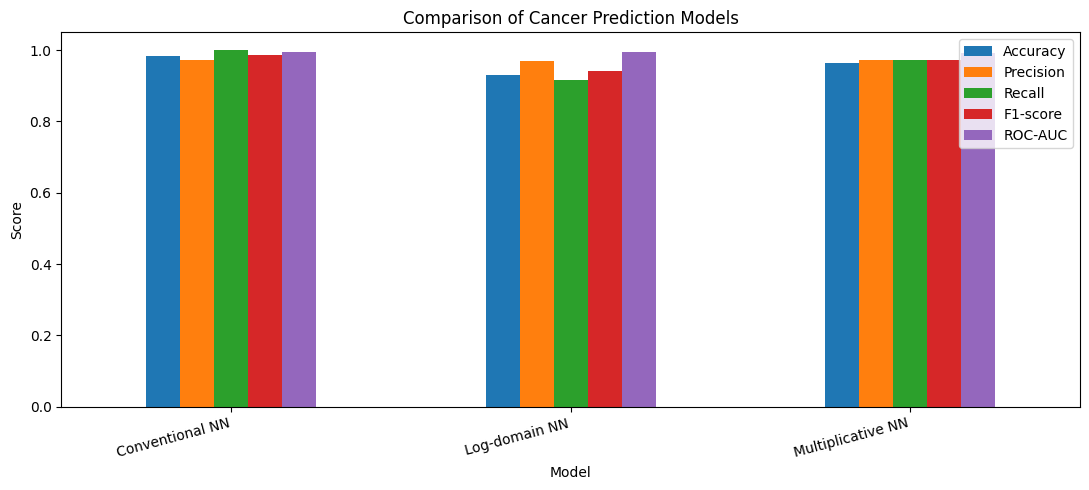

Comparison saved to final_model_comparison.csv


In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd
import matplotlib.pyplot as plt

def evaluate_model(model, X, y, name):
    probabilities = model.predict(X, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1-score": f1_score(y, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y, probabilities)
    }

results_final = pd.DataFrame([
    evaluate_model(
        standard_model, X_test_scaled, y_test,
        "Conventional NN"
    ),
    evaluate_model(
        multiplicative_model, X_test_log, y_test,
        "Log-domain NN"
    ),
    evaluate_model(
        true_multiplicative_model, X_test_scaled, y_test,
        "Multiplicative NN"
    )
])

display(results_final.round(4))

results_final.to_csv("final_model_comparison.csv", index=False)

results_final.set_index("Model").plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1.05)
)
plt.title("Comparison of Cancer Prediction Models")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

print("Comparison saved to final_model_comparison.csv")


In [ ]:

# Save the comparison table
results_final.to_csv(
    "cancer_model_comparison.csv",
    index=False
)

# Save the trained model
true_multiplicative_model.save(
    "multiplicative_cancer_model.keras"
)

print("Comparison table and trained model saved!")


Comparison table and trained model saved!


In [ ]:

import numpy as np

# Example positive inputs
x = np.array([2.0, 3.0, 4.0])

# Example learnable powers
w = np.array([0.5, 1.0, -0.5])

# Multiplicative neuron
y = np.prod(x ** w)

# Equivalent calculation using logarithms
y_log = np.exp(np.sum(w * np.log(x)))

print("Inputs:", x)
print("Powers:", w)
print("Multiplicative output:", round(y, 4))
print("Log-domain output:", round(y_log, 4))


Inputs: [2. 3. 4.]
Powers: [ 0.5  1.  -0.5]
Multiplicative output: 2.1213
Log-domain output: 2.1213


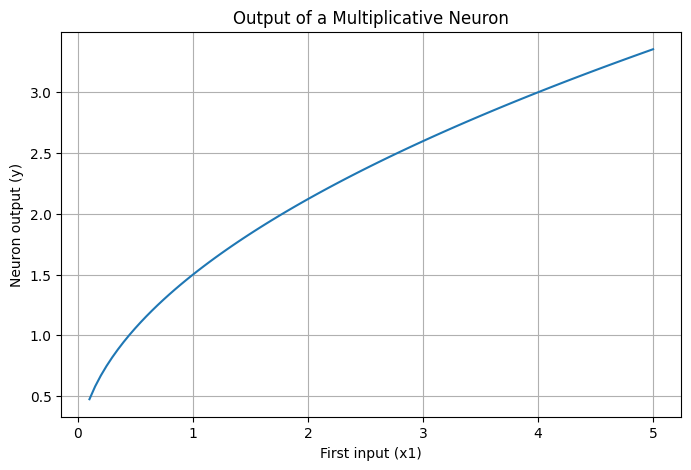

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Vary the first input
x1 = np.linspace(0.1, 5, 100)

# Keep the other inputs fixed
x2 = 3.0
x3 = 4.0

# Powers of the multiplicative neuron
w1, w2, w3 = 0.5, 1.0, -0.5

# Calculate the output for each value of x1
y = (x1 ** w1) * (x2 ** w2) * (x3 ** w3)

plt.figure(figsize=(8, 5))
plt.plot(x1, y)
plt.xlabel("First input (x1)")
plt.ylabel("Neuron output (y)")
plt.title("Output of a Multiplicative Neuron")
plt.grid(True)
plt.show()


In [ ]:

summary = """
PROJECT TITLE
Multiplicative Calculus-Based Neural Networks
for Breast Cancer Prediction

OBJECTIVE
To investigate a multiplicative neural-network architecture
for classifying breast cancer dataset samples as benign
or malignant, and compare its performance with a
conventional neural network.

DATASET
Wisconsin Diagnostic Breast Cancer dataset from scikit-learn.
The dataset contains 569 samples and 30 numerical features.

MODELS
1. Conventional neural network
2. Neural network using log-transformed inputs
3. Product-of-powers multiplicative neural network

EVALUATION METRICS
Accuracy, precision, recall, F1-score and ROC-AUC.

PRELIMINARY RESULTS
Conventional neural network: 98.25% accuracy
Log-domain neural network: 92.98% accuracy
Multiplicative neural network: 96.49% accuracy

LIMITATION
The multiplicative model is experimental.
Its mathematical relationship to multiplicative calculus
requires further formalization and validation.
These results do not establish clinical usefulness.

NEXT STEPS
Define the mathematical architecture, conduct robust
validation, analyze classification errors, and document
the experimental methodology.
"""

with open("project_research_summary.txt", "w") as file:
    file.write(summary)

print("Research summary saved!")


Research summary saved!


In [ ]:

import numpy as np

# Positive inputs and learnable powers
x = np.array([2.0, 3.0, 4.0])
w = np.array([0.5, 1.0, -0.5])

# Multiplicative neuron output
y = np.prod(x ** w)

# Ordinary derivative with respect to the first input
dy_dx1 = w[0] * y / x[0]

# Multiplicative derivative with respect to the first input
multiplicative_derivative = np.exp(dy_dx1 / y)

print("Neuron output:", round(y, 4))
print("Ordinary derivative:", round(dy_dx1, 4))
print(
    "Multiplicative derivative:",
    round(multiplicative_derivative, 4)
)


Neuron output: 2.1213
Ordinary derivative: 0.5303
Multiplicative derivative: 1.284


In [ ]:

import numpy as np

# Function: f(x) = x^2
def f(x):
    return x**2

# Point where we evaluate the derivative
x = 2.0
h = 1e-5

# Approximate ordinary derivative using finite differences
ordinary_derivative = (f(x + h) - f(x - h)) / (2 * h)

# Multiplicative derivative
multiplicative_derivative = np.exp(ordinary_derivative / f(x))

# Exact result for f(x) = x^2
exact_result = np.exp(2 / x)

print("Ordinary derivative:", round(ordinary_derivative, 5))
print("Numerical multiplicative derivative:",
      round(multiplicative_derivative, 5))
print("Exact multiplicative derivative:", round(exact_result, 5))


Ordinary derivative: 4.0
Numerical multiplicative derivative: 2.71828
Exact multiplicative derivative: 2.71828
